In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["font.family"] = "Arial"
import seaborn as sns

from scipy import stats

from additives_microbiota.constants import ADDITIVE_VARS, MIXTURES
from additives_microbiota.plotting import process_string, process_string_pretty_vars, pretty_var_names
from additives_microbiota.regression_modeling import fit_regression_model, calculate_vif, forest_plot


### Load metadata and merge NOVA features

In [2]:
meta = pd.read_csv("../../data/metadata_files/meta_zscores.csv", index_col=0)

bmi_order = ["Underweight", "Normal", "Overweight", "Obese"]
meta["bmi_cat"] = pd.Categorical(meta["bmi_cat"], categories=bmi_order, ordered=True)

meta["HEI_Quartile"] = meta["HEI_Quartile"].astype("category")
meta["HEI_Quartile"] = meta["HEI_Quartile"].cat.set_categories(
    ["Q1", "Q2", "Q3", "Q4"], ordered=True
)

meta["age_group_2"] = meta["age_group_2"].astype("category")
meta["age_group_2"] = meta["age_group_2"].cat.set_categories(
    ["<35", "35-50", ">50"], ordered=True
)

nova_meta_raw = pd.read_csv(
    "../../data/metadata_files/meta_with_food_subgroups_additives_nova.csv"
)
nova_cols = [c for c in nova_meta_raw.columns if c.startswith("nova_")]

meta_nova = meta.merge(
    nova_meta_raw[["subject_key"] + nova_cols],
    on="subject_key",
    how="left",
)

print("meta shape:", meta.shape)
print("meta_nova shape:", meta_nova.shape)
print("NOVA columns:", nova_cols)

meta shape: (975, 265)
meta_nova shape: (975, 280)
NOVA columns: ['nova_1_fg_eaten', 'nova_2_fg_eaten', 'nova_3_fg_eaten', 'nova_4_fg_eaten', 'nova_other_fg_eaten', 'nova_1_days_fraction', 'nova_2_days_fraction', 'nova_3_days_fraction', 'nova_4_days_fraction', 'nova_other_days_fraction', 'nova_1_cv', 'nova_2_cv', 'nova_3_cv', 'nova_4_cv', 'nova_other_cv']


In [3]:
NOVA_FG_FEATURES = [c for c in nova_cols if c.endswith("_fg_eaten")]
NOVA_DAY_FRACTION_FEATURES = [c for c in nova_cols if c.endswith("_days_fraction")]
NOVA_CV_FEATURES = [c for c in nova_cols if c.endswith("_cv")]

# Primary NOVA variables for modeling (exclude "nova_other_fg_eaten").
NOVA_PRIMARY_FEATURES = [c for c in NOVA_FG_FEATURES if c != "nova_other_fg_eaten"]

print("NOVA primary features:", NOVA_PRIMARY_FEATURES)

NOVA primary features: ['nova_1_fg_eaten', 'nova_2_fg_eaten', 'nova_3_fg_eaten', 'nova_4_fg_eaten']


## Correlation analysis

In [4]:
corr_targets = (
    ADDITIVE_VARS
    + MIXTURES
    + [
        "total_additive_intake",
        "vegetables_fruits",
        "shannon_entropy",
        "pielou_evenness",
        "observed_features",
        "faith_pd",
    ]
)

corr_table = (
    meta_nova[NOVA_PRIMARY_FEATURES + corr_targets]
    .corr()
    .loc[NOVA_PRIMARY_FEATURES, corr_targets]
)

corr_table

,thickeners_stabilizers_emulsifiers_gelling_agents,sweeteners_glazing_agents,preservatives_antioxidants,ph_regulators_anti_caking_leavening_agents,other_additives,flavor_enhancers,colorants,Mixture1,Mixture2,Mixture3,total_additive_intake,vegetables_fruits,shannon_entropy,pielou_evenness,observed_features,faith_pd
nova_1_fg_eaten,0.049765,0.136638,0.160037,-0.031933,0.072505,0.015289,0.053237,0.003379,-0.055629,0.179022,0.090862,0.718090,0.115882,0.114358,0.089738,0.039622
nova_2_fg_eaten,0.032340,0.004040,0.041606,-0.004922,0.060245,-0.011696,0.010976,0.019732,-0.035704,0.018827,0.016496,0.094711,0.008868,0.038845,-0.012401,0.002575
nova_3_fg_eaten,-0.028812,-0.047382,0.020567,0.033984,-0.061210,0.043343,0.002617,0.028603,0.049957,-0.084274,-0.012022,0.176052,-0.061615,-0.035002,-0.067619,-0.066498
nova_4_fg_eaten,0.370152,0.316811,0.282763,0.604581,0.081792,0.157763,0.505826,0.370797,0.605483,0.058129,0.544285,-0.041714,-0.170569,-0.163734,-0.144834,-0.133398


In [5]:
def pairwise_pearson(df, x_cols, y_cols):
    rows = []
    for x in x_cols:
        for y in y_cols:
            sub = df[[x, y]].dropna()
            if len(sub) < 3:
                continue
            r, p = stats.pearsonr(sub[x], sub[y])
            rows.append(
                {
                    "nova_feature": x,
                    "target_feature": y,
                    "n": len(sub),
                    "pearson_r": r,
                    "p_value": p,
                }
            )
    return pd.DataFrame(rows)


nova_vs_additives_corr = pairwise_pearson(
    meta_nova,
    NOVA_PRIMARY_FEATURES,
    ADDITIVE_VARS + ["total_additive_intake"],
)

nova_vs_additives_corr.sort_values(by="pearson_r", ascending=False).reset_index(
    drop=True
)

,nova_feature,target_feature,n,pearson_r,p_value
0,nova_4_fg_eaten,ph_regulators_anti_caking_leavening_agents,960,0.604581,9.719956e-97
1,nova_4_fg_eaten,total_additive_intake,960,0.544285,3.879386e-75
2,nova_4_fg_eaten,colorants,960,0.505826,1.691621e-63
3,nova_4_fg_eaten,thickeners_stabilizers_emulsifiers_gelling_agents,960,0.370152,1.534886e-32
4,nova_4_fg_eaten,sweeteners_glazing_agents,960,0.316811,8.002241e-24
5,nova_4_fg_eaten,preservatives_antioxidants,960,0.282763,4.160866e-19
6,nova_1_fg_eaten,preservatives_antioxidants,960,0.160037,6.219929e-07
7,nova_4_fg_eaten,flavor_enhancers,960,0.157763,8.990978e-07
8,nova_1_fg_eaten,sweeteners_glazing_agents,960,0.136638,2.156878e-05
9,nova_1_fg_eaten,total_additive_intake,960,0.090862,4.840939e-03


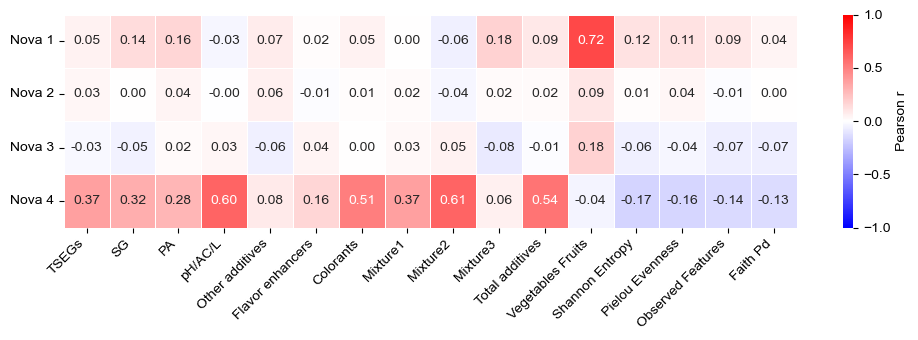

In [6]:
# Correlation heatmap for NOVA-primary features vs additive/diversity targets
plot_df = corr_table.copy()

x_labels = [process_string_pretty_vars(c) for c in plot_df.columns]
y_labels = [process_string_pretty_vars(r) for r in plot_df.index]

fig_height = max(3.0, 0.5 * len(plot_df.index) + 1.5)
plt.figure(figsize=(10, fig_height))

ax = sns.heatmap(
    plot_df,
    cmap="bwr",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Pearson r"},
)

ax.set_xticklabels(x_labels, rotation=45, ha="right")
ax.set_yticklabels(y_labels, rotation=0)

# plt.title("NOVA-primary vs additive and diversity correlations")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/correlation_nova_vs_additives.png",
    dpi=300,
    bbox_inches="tight",
)

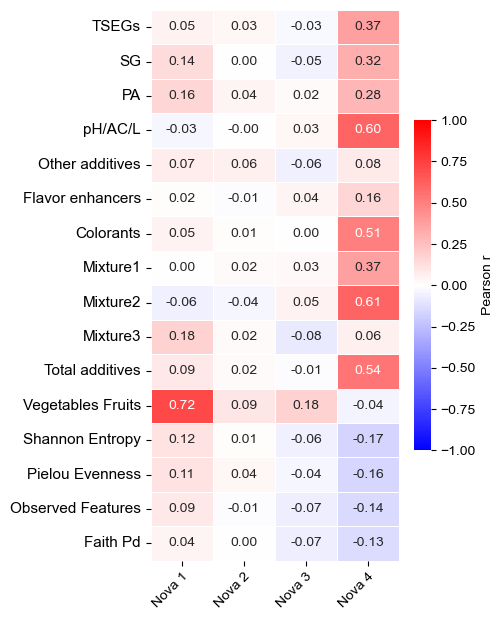

In [30]:
# Vertical orientation (transpose) of the same correlation heatmap
plot_df_vertical = corr_table.T.copy()

x_labels_vertical = [process_string_pretty_vars(c) for c in plot_df_vertical.columns]
y_labels_vertical = [process_string_pretty_vars(r) for r in plot_df_vertical.index]

fig_height_vertical = max(6.0, 0.3 * len(plot_df_vertical.index) + 1.5)
plt.figure(figsize=(5, fig_height_vertical))

ax = sns.heatmap(
    plot_df_vertical,
    cmap="bwr",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Pearson r", "shrink": 0.6},
)

ax.set_xticklabels(x_labels_vertical, rotation=45, ha="right", rotation_mode="anchor")
ax.set_yticklabels(y_labels_vertical, rotation=0, fontsize=11)

plt.xlabel("")
plt.ylabel("")
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/correlation_nova_vs_additives.png",
    dpi=300,
    bbox_inches="tight",
)

## Running OLS models

In [7]:
# Keep this as reference for available demographic covariates.
demographic_vars_all = [
    "age",
    "bmi",
    "C(gender)",
    "C(language, Treatment(reference='latin'))",
    "defecate_quantity_per_day",
    "C(urbanity, Treatment(reference='rural'))",
    "C(smoking, Treatment(reference='non-smoker'))",
    "energy_kcal_eaten",
    "C(antibiotics_treatment)",
    "alcohol_eaten",
    "batch",
]

demographic_vars_all

['age',
 'bmi',
 'C(gender)',
 "C(language, Treatment(reference='latin'))",
 'defecate_quantity_per_day',
 "C(urbanity, Treatment(reference='rural'))",
 "C(smoking, Treatment(reference='non-smoker'))",
 'energy_kcal_eaten',
 'C(antibiotics_treatment)',
 'alcohol_eaten',
 'batch']

In [8]:
continuous_covars = [
    "age",
    "bmi",
    "defecate_quantity_per_day",
    "energy_kcal_eaten",
    "alcohol_eaten",
]

categorical_covars = [
    "C(gender)",
    "C(language, Treatment(reference='latin'))",
    "C(urbanity, Treatment(reference='rural'))",
    "C(smoking, Treatment(reference='non-smoker'))",
    "C(antibiotics_treatment)",
    "batch",
]

model_scale_features = (
    ADDITIVE_VARS
    + ["total_additive_intake"]
    + MIXTURES
    + NOVA_PRIMARY_FEATURES
    + continuous_covars
)

meta_nova_scaled = meta_nova.copy()
for col in model_scale_features:
    meta_nova_scaled[col + "_z"] = (meta_nova[col] - meta_nova[col].mean()) / meta_nova[
        col
    ].std()

additive_models = {}
additive_model_rows = []

for additive in ADDITIVE_VARS + ["total_additive_intake"] + MIXTURES:
    predictors = [
        additive + "_z",
        *[n + "_z" for n in NOVA_PRIMARY_FEATURES],
    ]
    demographic_vars_scaled = [c + "_z" for c in continuous_covars] + categorical_covars

    model = fit_regression_model(
        meta_nova_scaled,
        predictors,
        demographic_vars=demographic_vars_scaled,
        dependent_var="shannon_entropy",
        robust_regression=False,
        do_robust_se=True,
    )

    additive_models[additive] = model
    additive_model_rows.append(
        {
            "additive_feature": additive,
            "coef_z": float(model.params.get(additive + "_z", np.nan)),
            "se_z": float(model.bse.get(additive + "_z", np.nan)),
            "p_value": float(model.pvalues.get(additive + "_z", np.nan)),
            "ci_low": float(model.conf_int().loc[additive + "_z", 0]),
            "ci_high": float(model.conf_int().loc[additive + "_z", 1]),
            "n_obs": int(model.nobs),
            "r_squared": float(model.rsquared),
        }
    )

additive_model_summary = pd.DataFrame(additive_model_rows).sort_values("p_value")
additive_model_summary

,additive_feature,coef_z,se_z,p_value,ci_low,ci_high,n_obs,r_squared
2,preservatives_antioxidants,-0.055632,0.019159,0.003689,-0.093184,-0.018080,925,0.196967
7,total_additive_intake,-0.065295,0.029017,0.024435,-0.122168,-0.008422,925,0.197925
10,Mixture3,-0.058729,0.029037,0.043116,-0.115639,-0.001818,925,0.199753
1,sweeteners_glazing_agents,-0.052755,0.030312,0.081792,-0.112166,0.006656,925,0.196589
0,thickeners_stabilizers_emulsifiers_gelling_agents,-0.031920,0.018734,0.088412,-0.068638,0.004798,925,0.191218
3,ph_regulators_anti_caking_leavening_agents,-0.037273,0.026784,0.164033,-0.089768,0.015222,925,0.191365
6,colorants,-0.029865,0.021738,0.169490,-0.072470,0.012741,925,0.190494
8,Mixture1,-0.029200,0.021636,0.177148,-0.071606,0.013206,925,0.190778
5,flavor_enhancers,-0.005005,0.015001,0.738646,-0.034407,0.024397,925,0.188449
9,Mixture2,0.005672,0.017346,0.743669,-0.028326,0.039671,925,0.188434


In [9]:
def _pretty_var_names_for_model(model):
    concise_label_overrides = {
        "Mixture1": "Mixture 1",
        "Mixture2": "Mixture 2",
        "Mixture3": "Mixture 3",
        "nova_1_fg_eaten": "NOVA 1",
        "nova_2_fg_eaten": "NOVA 2",
        "nova_3_fg_eaten": "NOVA 3",
        "nova_4_fg_eaten": "NOVA 4",
        "nova_other_fg_eaten": "NOVA other",
    }

    labels = {}
    for var in model.params.index:
        if var in ["Intercept"] or var.startswith("batch"):
            continue

        if var.endswith("_z"):
            base = var[:-2]
            if base in concise_label_overrides:
                labels[var] = concise_label_overrides[base] + " (z)"
            elif base in pretty_var_names:
                labels[var] = pretty_var_names[base] + " (z)"
            else:
                labels[var] = process_string_pretty_vars(base) + " (z)"
        else:
            if var in concise_label_overrides:
                labels[var] = concise_label_overrides[var]
            elif var in pretty_var_names:
                labels[var] = pretty_var_names[var]
            else:
                labels[var] = process_string_pretty_vars(var)

    return labels

### Testing for Total Additive Intake

In [10]:
# Inspect one model in detail and check VIFs.
test_additive = "total_additive_intake"
test_model = additive_models[test_additive]

print(f"test model: {test_additive}")
test_model.summary()

test model: total_additive_intake


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.198
Model:                            OLS   Adj. R-squared:                  0.178
Method:                 Least Squares   F-statistic:                     10.53
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           2.51e-32
Time:                        07:40:24   Log-Likelihood:                -629.73
No. Observations:                 925   AIC:                             1305.
Df Residuals:                     902   BIC:                             1417.
Df Model:                          22                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   6.4734      0.075     85.879      0.000       6.326       6.621
C(gender)[T.male]                                           0.0343      0.037      0.934      0.350      -0.038       0.106
C(language, Treatment(reference='latin'))[T.german]        -0.1009      0.037     -2.756      0.006      -0.173      -0.029
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0683      0.068     -1.000      0.317      -0.202       0.066
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1327      0.056     -2.365      0.018      -0.243      -0.023
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1091      0.035     -3.116      0.002      -0.178      -0.040
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.2195      0.059     -3.697      0.000      -0.336      -0.103
C(antibiotics_treatment)[T.True]                           -0.1276      0.070     -1.818      0.069      -0.265       0.010
batch[T.batch_0682]                                         0.0692      0.065      1.061      0.289      -0.059       0.197
batch[T.batch_1205]                                         0.1051      0.071      1.481      0.139      -0.034       0.244
batch[T.batch_1599]                                        -0.0689      0.070     -0.987      0.323      -0.206       0.068
batch[T.batch_2013]                                        -0.0028      0.069     -0.041      0.967      -0.139       0.133
batch[T.batch_2718]                                        -0.2235      0.070     -3.199      0.001      -0.360      -0.087
total_additive_intake_z                                    -0.0653      0.029     -2.250      0.024      -0.122      -0.008
nova_1_fg_eaten_z                                           0.0467      0.020      2.385      0.017       0.008       0.085
nova_2_fg_eaten_z                                           0.0037      0.013      0.290      0.772      -0.021       0.029
nova_3_fg_eaten_z                                          -0.0114      0.021     -0.545      0.586      -0.052       0.030
nova_4_fg_eaten_z                                          -0.0057      0.026     -0.217      0.829      -0.057       0.046
age_z                                                       0.0942      0.018      5.295      0.000       0.059       0.129
bmi_z                                                      -0.0540      0.017     -3.196      0.001      -0.087      -0.021
defecate_quantity_per_day_z                                -0.0861      0.017     -4.949      0.000      -0.120      -0.052
energy_kcal_eaten_z                                        -0.0003      0.022     -0.015      0.988      -0

~/miniconda3/envs/additives/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


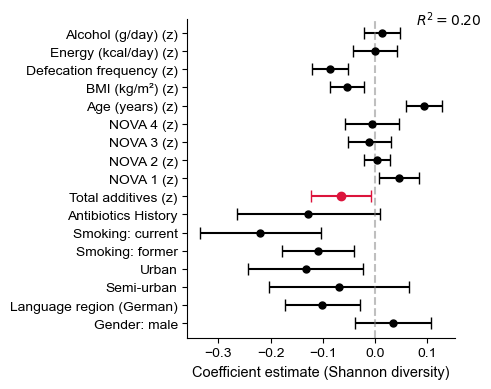

In [11]:
total_additive_model = additive_models["total_additive_intake"]

fig, ax = forest_plot(
    total_additive_model,
    title="",
    figsize=(5, 4),
    r2_annot_loc=(1.1, 1.03),
    pretty_var_names=_pretty_var_names_for_model(total_additive_model),
    highlight_vars=["total_additive_intake_z"],
    base_color="black",
    highlight_color="crimson",
)

sns.despine()
# plt.title("Model: NOVA + Total Additives")
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/additive_effects_modeling/forest_plot_nova_vs_total_additives.png",
    dpi=300,
    bbox_inches="tight",
)

In [12]:
calculate_vif(test_model, meta_nova_scaled)

,Variable,VIF
9,batch[T.batch_1599],2.789393
10,batch[T.batch_2013],2.760450
3,"C(urbanity, Treatment(reference='rural'))[T.ur...",2.636037
8,batch[T.batch_1205],2.622249
2,"C(urbanity, Treatment(reference='rural'))[T.se...",2.590257
11,batch[T.batch_2718],2.521598
7,batch[T.batch_0682],2.495061
20,energy_kcal_eaten_z,2.249143
16,nova_4_fg_eaten_z,1.771061
15,nova_3_fg_eaten_z,1.766105


### Testing for Mixture 3

In [13]:
# Inspect one model in detail and check VIFs.
test_additive = "Mixture3"
test_model = additive_models[test_additive]

print(f"test model: {test_additive}")
test_model.summary()

test model: Mixture3


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.200
Model:                            OLS   Adj. R-squared:                  0.180
Method:                 Least Squares   F-statistic:                     10.19
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           3.75e-31
Time:                        07:40:24   Log-Likelihood:                -628.68
No. Observations:                 925   AIC:                             1303.
Df Residuals:                     902   BIC:                             1414.
Df Model:                          22                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   6.4616      0.075     85.779      0.000       6.314       6.609
C(gender)[T.male]                                           0.0376      0.037      1.026      0.305      -0.034       0.109
C(language, Treatment(reference='latin'))[T.german]        -0.0949      0.037     -2.598      0.009      -0.166      -0.023
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0563      0.067     -0.834      0.404      -0.189       0.076
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1266      0.056     -2.272      0.023      -0.236      -0.017
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1114      0.035     -3.186      0.001      -0.180      -0.043
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.2152      0.060     -3.596      0.000      -0.332      -0.098
C(antibiotics_treatment)[T.True]                           -0.1331      0.070     -1.907      0.057      -0.270       0.004
batch[T.batch_0682]                                         0.0686      0.066      1.042      0.297      -0.060       0.197
batch[T.batch_1205]                                         0.1049      0.072      1.465      0.143      -0.035       0.245
batch[T.batch_1599]                                        -0.0759      0.070     -1.085      0.278      -0.213       0.061
batch[T.batch_2013]                                         0.0026      0.070      0.038      0.970      -0.135       0.140
batch[T.batch_2718]                                        -0.2144      0.071     -3.037      0.002      -0.353      -0.076
Mixture3_z                                                 -0.0587      0.029     -2.023      0.043      -0.116      -0.002
nova_1_fg_eaten_z                                           0.0503      0.020      2.523      0.012       0.011       0.089
nova_2_fg_eaten_z                                           0.0015      0.013      0.118      0.906      -0.024       0.027
nova_3_fg_eaten_z                                          -0.0116      0.020     -0.566      0.572      -0.052       0.029
nova_4_fg_eaten_z                                          -0.0380      0.020     -1.923      0.054      -0.077       0.001
age_z                                                       0.0938      0.018      5.291      0.000       0.059       0.129
bmi_z                                                      -0.0558      0.017     -3.338      0.001      -0.089      -0.023
defecate_quantity_per_day_z                                -0.0857      0.017     -4.910      0.000      -0.120      -0.051
energy_kcal_eaten_z                                        -0.0035      0.021     -0.163      0.871      -0

~/miniconda3/envs/additives/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


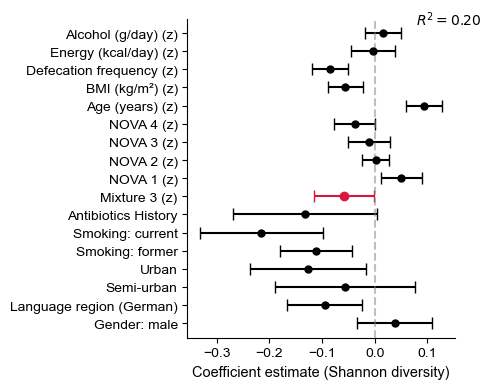

In [14]:
mixture3_model = additive_models["Mixture3"]

fig, ax = forest_plot(
    mixture3_model,
    title="",
    figsize=(5, 4),
    r2_annot_loc=(1.1, 1.03),
    pretty_var_names=_pretty_var_names_for_model(mixture3_model),
    highlight_vars=["Mixture3_z"],
    base_color="black",
    highlight_color="crimson",
)

sns.despine()
# plt.title("NOVA + Mixture 3")
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/additive_effects_modeling/forest_plot_nova_vs_mixture3.png",
    dpi=300,
    bbox_inches="tight",
)

# Test with Macronutrient

In [15]:
macro_continuous_covars = [
    "age",
    "bmi",
    "defecate_quantity_per_day",
    # "energy_kcal_eaten",
    "alcohol_eaten",
    "carb_eaten",
    "protein_eaten",
    "fat_eaten",
    "fiber_eaten",
    "HEI",
]

macro_categorical_covars = [
    "C(gender)",
    "C(language, Treatment(reference='latin'))",
    "C(urbanity, Treatment(reference='rural'))",
    "C(smoking, Treatment(reference='non-smoker'))",
    "C(antibiotics_treatment)",
    "batch",
]

macro_model_scale_features = (
    ADDITIVE_VARS + ["total_additive_intake"] + MIXTURES + macro_continuous_covars
)

meta_nova_macro_scaled = meta_nova.copy()
for col in macro_model_scale_features:
    meta_nova_macro_scaled[col + "_z"] = (
        meta_nova[col] - meta_nova[col].mean()
    ) / meta_nova[col].std()

macro_additive_models = {}
macro_additive_model_rows = []

for additive in ADDITIVE_VARS + ["total_additive_intake"] + MIXTURES:
    predictors = [
        additive + "_z",
    ]
    macro_demographic_vars_scaled = [
        c + "_z" for c in macro_continuous_covars
    ] + macro_categorical_covars

    model = fit_regression_model(
        meta_nova_macro_scaled,
        predictors,
        demographic_vars=macro_demographic_vars_scaled,
        dependent_var="shannon_entropy",
        robust_regression=False,
        do_robust_se=True,
    )

    macro_additive_models[additive] = model
    macro_additive_model_rows.append(
        {
            "additive_feature": additive,
            "coef_z": float(model.params.get(additive + "_z", np.nan)),
            "se_z": float(model.bse.get(additive + "_z", np.nan)),
            "p_value": float(model.pvalues.get(additive + "_z", np.nan)),
            "ci_low": float(model.conf_int().loc[additive + "_z", 0]),
            "ci_high": float(model.conf_int().loc[additive + "_z", 1]),
            "n_obs": int(model.nobs),
            "r_squared": float(model.rsquared),
        }
    )

macro_additive_model_summary = pd.DataFrame(macro_additive_model_rows).sort_values(
    "p_value"
)
macro_additive_model_summary

,additive_feature,coef_z,se_z,p_value,ci_low,ci_high,n_obs,r_squared
2,preservatives_antioxidants,-0.048445,0.017313,0.005139,-0.082378,-0.014512,940,0.209703
7,total_additive_intake,-0.052045,0.023205,0.024905,-0.097525,-0.006565,940,0.211029
1,sweeteners_glazing_agents,-0.055332,0.027382,0.043302,-0.108999,-0.001665,940,0.212685
10,Mixture3,-0.058192,0.030949,0.060077,-0.118852,0.002468,940,0.213749
6,colorants,-0.027644,0.017211,0.108223,-0.061377,0.006088,940,0.205061
0,thickeners_stabilizers_emulsifiers_gelling_agents,-0.026513,0.017481,0.129351,-0.060776,0.007749,940,0.204850
3,ph_regulators_anti_caking_leavening_agents,-0.031582,0.021497,0.141792,-0.073714,0.010551,940,0.205716
9,Mixture2,-0.015351,0.014614,0.293508,-0.043994,0.013291,940,0.203452
8,Mixture1,-0.019812,0.019969,0.321132,-0.058950,0.019326,940,0.203816
4,other_additives,0.002511,0.015372,0.870222,-0.027616,0.032639,940,0.202675


~/miniconda3/envs/additives/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


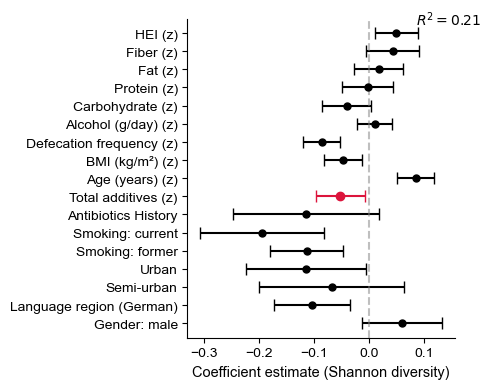

In [16]:
macro_total_additive_model = macro_additive_models["total_additive_intake"]

fig, ax = forest_plot(
    macro_total_additive_model,
    title="",
    figsize=(5, 4),
    r2_annot_loc=(1.1, 1.03),
    pretty_var_names=_pretty_var_names_for_model(macro_total_additive_model),
    highlight_vars=["total_additive_intake_z"],
    base_color="black",
    highlight_color="crimson",
)

sns.despine()
# plt.title("NOVA + Mixture 3")
plt.tight_layout()